# Лабораторна робота № 7
## Діагностика моделей: відхилення, дисперсія, розбіжність даних і пріоритизація помилок

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали · лекції 9–10

---

### Постановка

Ви — аналітик сервісу, який читає рукописні цифри з бланків. Перші моделі навчали на
**сканах**: 20 000 чітких цифр. Тепер клієнти надсилають **фото з телефона**, і модель на них
помиляється значно частіше. У кожного варіанта — свій «телефон»: свої вади зйомки, яких вам
ніхто не опише.

Попередній аналітик залишив **виробничу модель** і пішов. Вам треба:

1. **поставити діагноз** виробничій моделі: відхилення, дисперсія чи розбіжність даних;
2. **знайти і впорядкувати за впливом** причини помилок на телефонних фото;
3. **скласти план дій** з обмеженим бюджетом і перевірити його числами.

> **Головне правило лабораторної.** Кожне твердження у звіті підкріплюється числом, яке ви
> отримали в цьому ноутбуці. «Модель перенавчилась» без двох похибок поруч — не діагноз.

| Частина | Що робите | Бали |
|---|---|---|
| 1 | відхилення і дисперсія: чотири вибірки, людський рівень, криві навчання, дії | 1,5 |
| 2 | різні розподіли: розклад похибки, аналіз 100 помилок, ліки з бюджетом, план, аналіз за частинами, критика звіту колеги | 2,0 |
| 3 | звіт і декларація про використання ШІ | 0,5 |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Паничевська Ярина Ернестівна'     
LIST_NUMBER  = 15      

In [2]:
assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
print('варіант', VARIANT)

варіант 15


> Поряд із ноутбуком має лежати тека `дані/` з файлами `скани.npz`,
> `lr7_варіанти_студенту.json` і **файлом вашого варіанта** `lr7_варіант_NN.npz`
> (кожен варіант — окремий файл близько 5 МБ; завантажте свій із ВНС).

In [3]:
import importlib.util, subprocess, sys
REQUIRED = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']
MODNAME = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [4]:
import warnings; warnings.filterwarnings('ignore')
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

DATA_DIR = 'дані'
C1, C2, C3, C4, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#c0392b', '#8a8a8a'
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
print('scikit-learn', sklearn.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | numpy 2.3.5


### Допоміжні функції

Їх не треба змінювати — лише розуміти, що вони роблять. Опис кожної — у рядку документації.

In [5]:
import numpy as np
from scipy import ndimage as ndi


def flat(X):
    """Зображення uint8 (n, 28, 28) → ознаки у [0, 1], форма (n, 784)."""
    return X.reshape(len(X), -1).astype(np.float32) / 255.0


def split_train_dev(n, n_dev, seed=7):
    """Індекси навчальної частини і навчально-валідаційної вибірки (training dev set)."""
    perm = np.random.default_rng(seed).permutation(n)
    return perm[n_dev:], perm[:n_dev]


def _rotate(im, deg):
    t = np.deg2rad(deg); mat = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    c = np.array(im.shape) / 2 - 0.5
    return ndi.affine_transform(im, mat, offset=c - mat @ c, order=1, mode='constant', cval=0.0)


def distort(X, seed, angle=None, blur=None, lowres=None, background=None, contrast=None, glare=None, noise=None, share=1.0):
    """Синтез «телефонних» фото з чистих цифр. Кожен параметр — пара (від, до), з якої
    для кожного зображення береться випадкове значення; None — властивість вимкнено.
    share — частка зображень, до яких застосовують задані властивості (решта лишається чистою).
      angle      — кут повороту, градуси (знак обирається випадково)
      blur       — сигма гаусового розмиття, пікселі
      lowres     — до якої роздільності стиснути і розтягнути назад, пікселі (наприклад, (9, 12))
      background — яскравість фону, 0..1;  contrast — множник яскравості штрихів, 0..1
      glare      — сила відблиску (пляма, у якій штрихи «вигорають» до кольору фону), 0..1
      noise      — стандартне відхилення шуму сенсора
    Повертає uint8 (n, 28, 28)."""
    rng = np.random.default_rng(seed); out = np.empty(X.shape, np.float32)
    yy, xx = np.mgrid[0:28, 0:28]
    u = lambda r: rng.uniform(*r)
    for k, im in enumerate(X.astype(np.float32) / 255):
        if rng.random() < share:
            if angle: im = _rotate(im, rng.choice([-1, 1]) * u(angle))
            if blur: im = ndi.gaussian_filter(im, u(blur))
            if lowres:
                L = int(round(u(lowres))); im = ndi.zoom(ndi.zoom(im, L / 28, order=1), 28 / L, order=1)[:28, :28]
            bg = u(background) if background else 0.0
            im = bg + (u(contrast) if contrast else 1.0) * im
            if glare:
                cy, cx = rng.uniform(8, 20, 2); sg = rng.uniform(3.5, 6.5)
                w = u(glare) * np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * sg * sg)); im = im * (1 - w) + w * bg
            if noise: im = im + rng.normal(0, u(noise), im.shape)
        out[k] = np.clip(im, 0, 1)
    return (out * 255).round().astype(np.uint8)


def image_stats(X):
    """Прості вимірювання кожного фото за пікселями — ними можна відбирати фото без міток."""
    rows = []
    yy, xx = np.mgrid[0:28, 0:28]
    for im in X.astype(np.float32) / 255:
        p50, p99 = np.percentile(im, [50, 99]); ink = np.clip(im - p50, 0, None); m = ink.sum() + 1e-9
        cy, cx = (ink * yy).sum() / m, (ink * xx).sum() / m
        mu20, mu02, mu11 = (ink * (xx - cx) ** 2).sum() / m, (ink * (yy - cy) ** 2).sum() / m, (ink * (xx - cx) * (yy - cy)).sum() / m
        rows.append({'контраст': p99 - p50,
                     'різкість': float(ndi.laplace(ndi.gaussian_filter(im, 0.5)).var()),
                     'нахил_осі': float(np.degrees(0.5 * np.arctan2(2 * mu11, mu02 - mu20))),
                     'шум': float((im - ndi.median_filter(im, 3)).std()),
                     'частка_чорнила': float((im > p50 + 0.5 * (p99 - p50)).mean())})
    return rows


def make_canvas(photos, seed, blobs=(1, 3), lines=0):
    """Полотна 56×56: телефонне фото цифри в довільному місці; плями-завади поза цифрою
    і (за потреби) lines горизонтальних ліній бланка. Повертає полотна (float 0..1) і справжні положення."""
    r = np.random.default_rng(seed); n = len(photos)
    X = np.clip(0.1 + r.normal(0, 0.04, (n, 56, 56)), 0, 1).astype(np.float32); pos = np.zeros((n, 2), int)
    yy, xx = np.mgrid[0:56, 0:56]
    for i in range(n):
        rr, cc = r.integers(0, 29, 2); pos[i] = (rr, cc)
        X[i, rr:rr + 28, cc:cc + 28] = np.maximum(X[i, rr:rr + 28, cc:cc + 28], photos[i].astype(np.float32) / 255)
        for _ in range(r.integers(blobs[0], blobs[1] + 1)):
            while True:
                br, bc = r.integers(2, 54, 2)
                if not (rr - 3 <= br <= rr + 30 and cc - 3 <= bc <= cc + 30):
                    break
            s, a = r.uniform(1.2, 2.2), r.uniform(0.5, 0.9)
            X[i] = np.maximum(X[i], 0.1 + a * np.exp(-((yy - br) ** 2 + (xx - bc) ** 2) / (2 * s * s)))
        for _ in range(lines):
            ly = r.integers(4, 52); X[i, ly:ly + 2, :] = np.maximum(X[i, ly:ly + 2, :], r.uniform(0.45, 0.7))
    return np.clip(X, 0, 1), pos


def locate(X, thr=0.3):
    """Компонент A (без навчання): лівий верхній кут вирізу 28×28 навколо цифри."""
    out = np.zeros((len(X), 2), int)
    for i, im in enumerate(X):
        ink = np.clip(ndi.gaussian_filter(im, 0.7) - thr, 0, None)
        s = ndi.uniform_filter(ink, size=28, mode='constant')[14:43, 14:43]
        r0, c0 = np.unravel_index(np.argmax(s), s.shape)
        w = ink[r0:r0 + 28, c0:c0 + 28].copy(); lab, n = ndi.label(w > 0)
        if n > 1:
            w[lab != 1 + np.argmax(ndi.sum(w, lab, range(1, n + 1)))] = 0
        m = w.sum() + 1e-9; cy = (w.sum(1) * np.arange(28)).sum() / m; cx = (w.sum(0) * np.arange(28)).sum() / m
        out[i] = (int(np.clip(round(r0 + cy - 14), 0, 28)), int(np.clip(round(c0 + cx - 14), 0, 28)))
    return out


def crop(X, pos):
    """Вирізи 28×28 у форматі uint8, як фото."""
    return (np.stack([X[i, p[0]:p[0] + 28, p[1]:p[1] + 28] for i, p in enumerate(pos)]) * 255).round().astype(np.uint8)


def shifted_copies(X, seed, k=2):
    """Копії зображень, зсунуті на випадкові ±k пікселів: класифікатор після локалізатора має їх витримувати."""
    r = np.random.default_rng(seed); out = np.empty_like(X)
    for i in range(len(X)):
        dy, dx = r.integers(-k, k + 1, 2); out[i] = np.roll(np.roll(X[i], dy, 0), dx, 1)
    return out

In [6]:
def err(model, X, y):
    """Похибка у відсотках (частка неправильних відповідей × 100)."""
    return round(100 * float((model.predict(X) != y).mean()), 2)


def show_grid(images, titles=None, ncol=10, size=1.05, title=None):
    """Сітка зображень; темне — чорнило."""
    n = len(images); nrow = (n + ncol - 1) // ncol
    fig, axs = plt.subplots(nrow, ncol, figsize=(size * ncol, size * nrow + (0.35 if title else 0) + 0.25 * nrow))
    for k, ax in enumerate(np.ravel(axs)):
        ax.axis('off')
        if k < n:
            ax.imshow(images[k], cmap='gray_r', vmin=0, vmax=255 if np.asarray(images[k]).max() > 1 else 1)
            if titles:
                ax.set_title(titles[k], fontsize=8)
    if title:
        fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()


_TEST_CALLS = []


def evaluate_on_test(model, name):
    """Остаточна оцінка на тестовій вибірці. Викликайте ОДИН раз — для обраної моделі."""
    _TEST_CALLS.append(name)
    if len(_TEST_CALLS) > 1:
        print('УВАГА: тестову вибірку використано вже', len(_TEST_CALLS), 'рази — це буде видно у звіті')
    return err(model, flat(TEST_X), TEST_Y)

### Дані

| Масив | Що це | Скільки |
|---|---|---|
| `SCAN_X`, `SCAN_Y` | скани: чіткі цифри | 20 000 |
| `PHONE_X`, `PHONE_Y` | телефонні фото з мітками, для навчання | 2000 |
| `POOL_X`, `POOL_Y` | телефонні фото, які можна **докупити** (частина 2; бюджет — 1000 штук) | 2000 |
| `DEV_X`, `DEV_Y` | валідаційна вибірка: телефонні фото | 1500 |
| `TEST_X`, `TEST_Y` | тестова вибірка: телефонні фото — **лише для остаточної оцінки** | 1500 |
| `HUMAN_X` | 50 фото для вимірювання людського рівня (мітки приховано) | 50 |

Валідаційна і тестова вибірки — з того розподілу, на якому сервіс має працювати:
телефонні фото (лекція 10, розділ 36).

In [7]:
S = np.load(os.path.join(DATA_DIR, 'скани.npz'))
V = np.load(os.path.join(DATA_DIR, 'lr7_варіант_%02d.npz' % VARIANT))
with open(os.path.join(DATA_DIR, 'lr7_варіанти_студенту.json'), encoding='utf-8') as f:
    INFO = json.load(f)[VARIANT - 1]
SCAN_X, SCAN_Y = S['scan_X'], S['scan_y']
PHONE_X, PHONE_Y = V['phone_train_X'], V['phone_train_y']
POOL_X, POOL_Y = V['pool_X'], V['pool_y']
DEV_X, DEV_Y = V['dev_X'], V['dev_y']
TEST_X, TEST_Y = V['test_X'], V['test_y']
HUMAN_X, HUMAN_CODE = V['human_X'], V['human_code']
for nm in ['SCAN_X', 'PHONE_X', 'POOL_X', 'DEV_X', 'TEST_X', 'HUMAN_X']:
    print('%-8s' % nm, globals()[nm].shape)
print()
print('Виробнича модель попереднього аналітика:')
print('  навчена на:', INFO['виробнича']['навчена_на'])
print('  модель:    ', INFO['виробнича']['модель'])

SCAN_X   (20000, 28, 28)
PHONE_X  (2000, 28, 28)
POOL_X   (2000, 28, 28)
DEV_X    (1500, 28, 28)
TEST_X   (1500, 28, 28)
HUMAN_X  (50, 28, 28)

Виробнича модель попереднього аналітика:
  навчена на: телефон
  модель:     MLPClassifier(hidden_layer_sizes=(512,), alpha=1e-6, max_iter=300, random_state=0)


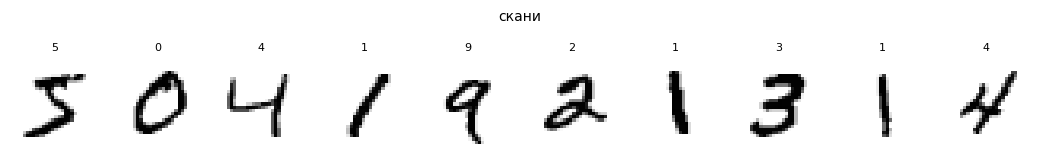

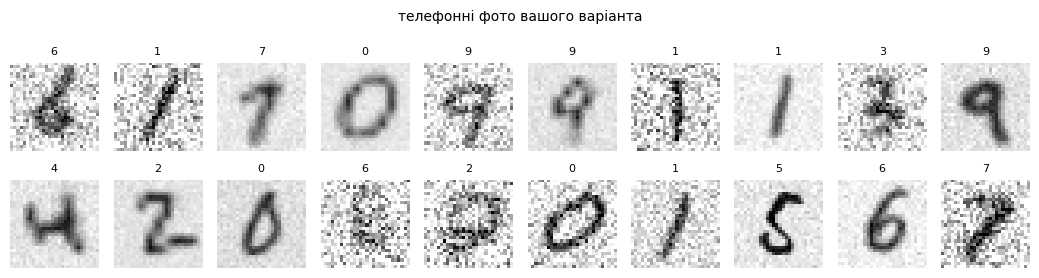

In [8]:
show_grid(SCAN_X[:10], [str(v) for v in SCAN_Y[:10]], title='скани')
show_grid(PHONE_X[:20], [str(v) for v in PHONE_Y[:20]], title='телефонні фото вашого варіанта')

---
# Частина 1. Відхилення і дисперсія (1,5 бала)
---
## 1. Чотири вибірки

Щоб розрізнити дисперсію і розбіжність даних, потрібна **навчально-валідаційна вибірка**
(training dev set): приклади з **того самого розподілу, на якому вчилася модель**, але не
показані їй під час навчання (лекція 10, розділ 40).

Виробнича модель навчалась на джерелі, назва якого надрукована вище. Оберіть те саме
джерело і відкладіть із нього навчально-валідаційну вибірку:

| джерело | що це | скільки відкласти |
|---|---|---|
| `'скани'` | лише 20 000 сканів | 2000 |
| `'телефон'` | лише 2000 телефонних фото | 400 |
| `'суміш'` | 20 000 сканів + 2000 фото | 2000 |

### Завдання 1.1

In [ ]:
TRAIN_SOURCE = 'телефон'

WHY_TRAIN_DEV = 'Навчально-валідаційна вибірка має бути з того самого розподілу, на якому вчилася модель, тому що тоді модель не бачила цих даних, але вони такі самі, як навчальні. Якщо похибка на них більша, ніж на навчальних, це точно перенавчання, а не те, що дані інші.'


In [10]:
SOURCES = {'скани': (SCAN_X, SCAN_Y), 'телефон': (PHONE_X, PHONE_Y),
           'суміш': (np.concatenate([SCAN_X, PHONE_X]), np.concatenate([SCAN_Y, PHONE_Y]))}
N_TRAIN_DEV = {'скани': 2000, 'телефон': 400, 'суміш': 2000}
assert TRAIN_SOURCE in SOURCES, 'оберіть одне з трьох джерел'
assert WHY_TRAIN_DEV, 'поясніть вибір'
SRC_X, SRC_Y = SOURCES[TRAIN_SOURCE]
idx_tr, idx_td = split_train_dev(len(SRC_Y), N_TRAIN_DEV[TRAIN_SOURCE])
X_tr, y_tr = flat(SRC_X[idx_tr]), SRC_Y[idx_tr]
X_td, y_td = flat(SRC_X[idx_td]), SRC_Y[idx_td]
X_dev, y_dev = flat(DEV_X), DEV_Y
print(f'навчальна: {len(y_tr)} | навчально-валідаційна: {len(y_td)} | валідаційна: {len(y_dev)} | тестова: {len(TEST_Y)} (не чіпаємо)')

навчальна: 1600 | навчально-валідаційна: 400 | валідаційна: 1500 | тестова: 1500 (не чіпаємо)


## 2. Людський рівень

Оптимальну похибку ми не знаємо, тож оцінюємо її **людським рівнем** — найкращим, якого
досягає людина на тих самих фото (лекція 10, розділи 33–34). Подивіться на 50 фото свого
варіанта і впишіть цифри підряд — 50 символів, пробіли не важливі. Не збільшуйте зображення
більше, ніж його бачить модель, і не підглядайте в мітки.

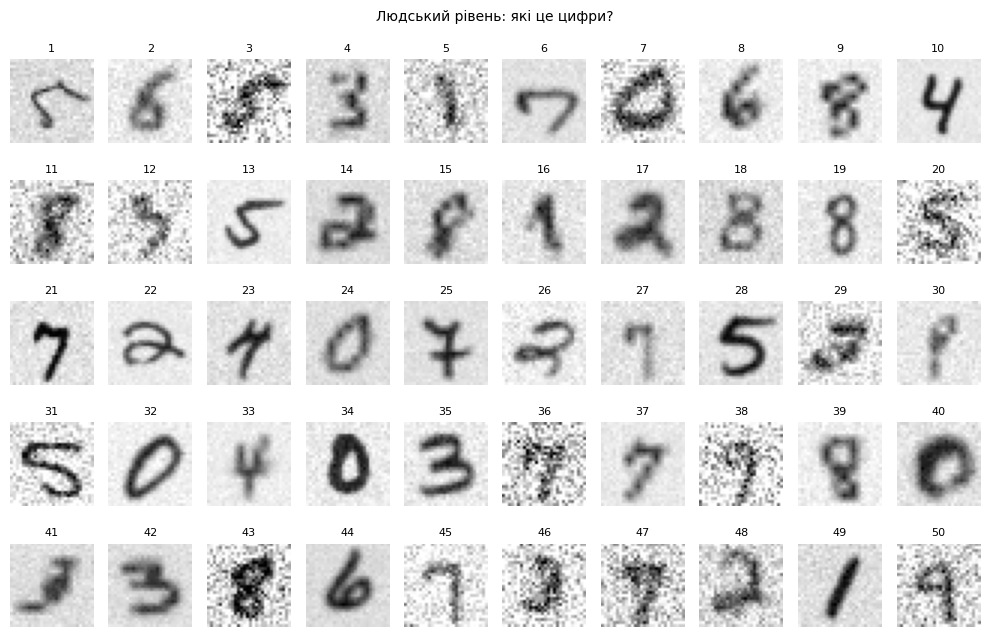

In [11]:
show_grid(HUMAN_X, [str(k + 1) for k in range(50)], size=1.0, title='Людський рівень: які це цифри?')

### Завдання 2.1

In [12]:
HUMAN_ANSWERS = '56531706348352812885724073757150403779803386737219'

In [13]:
ans = [int(c) for c in HUMAN_ANSWERS if c.isdigit()]
assert len(ans) == 50, f'потрібно 50 цифр, а введено {len(ans)}'
truth = (HUMAN_CODE - 7 * np.arange(50)) % 10
HUMAN_ERR = round(100 * float(np.mean(np.array(ans) != truth)), 1)
print('ваша похибка на 50 фото:', HUMAN_ERR, '%')
print('номери фото, де ви помилились:', [k + 1 for k in range(50) if ans[k] != truth[k]])

ваша похибка на 50 фото: 8.0 %
номери фото, де ви помилились: [9, 26, 29, 30]


> **Одна помилка на 50 фото — це 2 %, і довірчий інтервал такої оцінки широкий.**
> Як людський рівень беріть найкращий результат, якого досягла людина на цих фото: якщо
> одногрупник із тим самим варіантом має менше помилок — використайте його число і
> зазначте це у звіті.

## 3. Діагноз виробничої моделі

Відтворюємо виробничу модель і рахуємо похибки на трьох вибірках. Розклад (лекція 10, розділ 41):

$$\underbrace{E_{\text{навч}} - E_{\text{людина}}}_{\text{усувне відхилення}},\qquad
\underbrace{E_{\text{навч-вал}} - E_{\text{навч}}}_{\text{дисперсія}},\qquad
\underbrace{E_{\text{вал}} - E_{\text{навч-вал}}}_{\text{розбіжність даних}}$$

In [14]:
PRODUCTION = eval(INFO['виробнича']['модель'])
t0 = time.time()
prod = PRODUCTION.fit(X_tr, y_tr)
E_PROD = {'навч': err(prod, X_tr, y_tr), 'навч_вал': err(prod, X_td, y_td), 'вал': err(prod, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с')
print('похибки виробничої моделі, %:', E_PROD)
DECOMP_PROD = {'усувне відхилення': round(E_PROD['навч'] - HUMAN_ERR, 2),
               'дисперсія': round(E_PROD['навч_вал'] - E_PROD['навч'], 2),
               'розбіжність даних': round(E_PROD['вал'] - E_PROD['навч_вал'], 2)}
pd.Series(DECOMP_PROD, name='п. п.').to_frame()

навчено за 32 с
похибки виробничої моделі, %: {'навч': 0.0, 'навч_вал': 13.75, 'вал': 14.4}


,п. п.
усувне відхилення,-8.00
дисперсія,13.75
розбіжність даних,0.65


### Завдання 3.1

Поставте діагноз. Якщо дві складові близькі, назвіть головну і поясніть, чому друга —
другорядна.

In [15]:
DIAGNOSIS = 'дисперсія'
DIAGNOSIS_WHY = 'Похибка на навчальній вибірці 0,0 %, а на навчально-валідаційній 13,75 %: різниця 13,75 п. п. — це дисперсія. Розбіжність даних лише 0,65 п. п. (14,4 % на валідаційній і 13,75 % на навчально-валідаційній), а усувне відхилення від\'ємне (−8 п. п.), тож головна складова — дисперсія.'



In [16]:
assert DIAGNOSIS in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_WHY, 'заповніть діагноз і доказ'
print('діагноз:', DIAGNOSIS)

діагноз: дисперсія


## 4. Крива навчання

Крива навчання показує, чи допоможуть **ще дані того самого розподілу** (лекція 9, розділи 28–30).
Навчаємо виробничу модель на 10, 25, 50 і 100 % навчальної частини і дивимось на похибку на
навчальній і навчально-валідаційній вибірках; пунктиром — валідаційна похибка повної моделі
і ваш людський рівень. Це триває 1–3 хвилини.

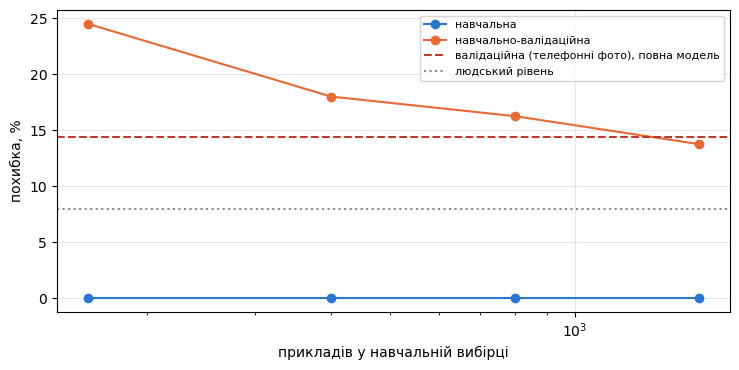

,n,навч,навч_вал
0,160,0.0,24.50
1,400,0.0,18.00
2,800,0.0,16.25
3,1600,0.0,13.75


In [17]:
curve = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    n = max(50, int(len(y_tr) * frac))
    m = eval(INFO['виробнича']['модель']).fit(X_tr[:n], y_tr[:n])
    curve.append({'n': n, 'навч': err(m, X_tr[:n], y_tr[:n]), 'навч_вал': err(m, X_td, y_td)})
CURVE = pd.DataFrame(curve)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(CURVE['n'], CURVE['навч'], 'o-', color=C1, label='навчальна')
ax.plot(CURVE['n'], CURVE['навч_вал'], 'o-', color=C2, label='навчально-валідаційна')
ax.axhline(E_PROD['вал'], ls='--', color=C4, label='валідаційна (телефонні фото), повна модель')
ax.axhline(HUMAN_ERR, ls=':', color=GREY, label='людський рівень')
ax.set_xscale('log'); ax.set_xlabel('прикладів у навчальній вибірці'); ax.set_ylabel('похибка, %')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
CURVE

### Завдання 4.1

In [18]:
MORE_SAME_DATA_HELPS = True
CURVE_WHY = 'Навчальна похибка весь час 0 %, а навчально-валідаційна падає зі зростанням даних. Між кривими великий розрив (13,75 п. п. на повній вибірці) і він ще не закрився, отже модель страждає від дисперсії, і більше даних того самого джерела мають її зменшити. Валідаційна лінія (14,4 %) лежить майже на навчально-валідаційній, тому розбіжність даних мала. Людський рівень (8 %) нижче обох кривих, тож резерв для покращення є.'

In [19]:
assert MORE_SAME_DATA_HELPS in (True, False) and CURVE_WHY, 'заповніть висновок за кривою'

## 5. Дії: що допомагає, а що — ні

Таблиці лекції 9 (розділи 25 і 27) кажуть, які дії зменшують відхилення, а які — дисперсію;
лекція 10 (розділи 37–43) — що робити з розбіжністю. Перевірте це на своїй моделі:

* **дві дії**, які, за вашим діагнозом, мають допомогти;
* **одну контрольну дію**, спрямовану на **іншу** проблему, — вона допомогти не повинна.

Кожна дія — це модель і навчальні дані. Похибки рахуються на тих самих навчально-валідаційній
і валідаційній вибірках, що й у пункті 3. Готові «цеглинки»:
`X_tr, y_tr` — навчальна частина вашого джерела; `flat(SCAN_X), SCAN_Y` — усі скани;
`flat(PHONE_X), PHONE_Y` — усі телефонні фото (увага: частина з них — у навчально-валідаційній
вибірці, якщо джерело `'телефон'` чи `'суміш'`; використовуйте `X_tr` і додавайте до нього
лише те, чого в ній немає); `SRC_X[idx_tr]` — ті самі навчальні приклади як зображення, з яких
`shifted_copies(SRC_X[idx_tr], seed, k)` робить копії, зсунуті на ±k пікселів (аугментація);
`distort(...)` — синтез «телефонних» фото (опис — у розділі 8).

Приклад запису:

```python
('більша модель: MLP(256)', 'відхилення',
 MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0), X_tr, y_tr)
```

Одна дія навчається від кількох секунд до хвилини.

In [20]:
ACTIONS = [
    ('+ дані: сильніша регуляризація', 'дисперсія',
     MLPClassifier(hidden_layer_sizes=(512,), alpha=1, max_iter=300, random_state=0), X_tr, y_tr),

    ('аугментація: зсуви +-2 px', 'дисперсія',
     MLPClassifier(hidden_layer_sizes=(512,), alpha=1e-6, max_iter=300, random_state=0),
     np.concatenate([X_tr, flat(shifted_copies(SRC_X[idx_tr], 1, 2))]),
     np.concatenate([y_tr, y_tr])),

    ('більша модель: MLP(1024)', 'відхилення',
     MLPClassifier(hidden_layer_sizes=(1024,), alpha=1e-6, max_iter=300, random_state=0), X_tr, y_tr),
]

In [21]:
assert len(ACTIONS) >= 3, 'потрібно щонайменше три дії: дві за діагнозом і одна контрольна'
rows = [{'дія': 'виробнича модель (до змін)', 'на що спрямована': '—', **E_PROD}]
for name, target, model, Xa, ya in ACTIONS:
    t0 = time.time(); model.fit(Xa, ya)
    rows.append({'дія': name, 'на що спрямована': target, 'навч': err(model, Xa, ya),
                 'навч_вал': err(model, X_td, y_td), 'вал': err(model, X_dev, y_dev)})
    print(f'{name}: {time.time() - t0:.0f} с')
ACT_TABLE = pd.DataFrame(rows)
ACT_TABLE['Δ дисперсії, п. п.'] = (ACT_TABLE['навч_вал'] - ACT_TABLE['навч']) - (E_PROD['навч_вал'] - E_PROD['навч'])
ACT_TABLE['Δ відхилення, п. п.'] = ACT_TABLE['навч'] - E_PROD['навч']
ACT_TABLE['Δ валідаційної, п. п.'] = ACT_TABLE['вал'] - E_PROD['вал']
ACT_TABLE.round(2)

+ дані: сильніша регуляризація: 18 с
аугментація: зсуви +-2 px: 46 с
більша модель: MLP(1024): 43 с


,дія,на що спрямована,навч,навч_вал,вал,"Δ дисперсії, п. п.","Δ відхилення, п. п.","Δ валідаційної, п. п."
0,виробнича модель (до змін),—,0.00,13.75,14.40,0.00,0.00,0.00
1,+ дані: сильніша регуляризація,дисперсія,1.56,13.25,12.47,-2.06,1.56,-1.93
2,аугментація: зсуви +-2 px,дисперсія,0.00,11.25,11.33,-2.50,0.00,-3.07
3,більша модель: MLP(1024),відхилення,0.00,14.50,13.67,0.75,0.00,-0.73


### Завдання 5.1

In [22]:
ACTIONS_CONCLUSION = 'Аугментація зсувами +-2 px допомогла найбільше: дисперсія впала на 2,50 п. п., валідаційна похибка — на 3,07 п. п.. Сильніша регуляризація теж допомогла: дисперсія −2,0 п. п., валідаційна −1,93 п. п.. Контрольна дія  не допомогла: навчальна похибка лишилась 0 %, дисперсія навіть зросла на 0,75 п. п. ; зміна валідаційної (−0,73 п. п.). Прогноз справдився: відхилення вже нульове, тож збільшення моделі нічого не дає.'


In [23]:
assert ACTIONS_CONCLUSION, 'сформулюйте висновок'

---
# Частина 2. Різні розподіли і пріоритизація помилок (2,0 бала)
---
## 6. Модель B і розклад її похибки

Далі працюємо з моделлю, яку радить лекція 10 (розділ 37): велика мережа на **суміші** сканів і
телефонних фото. Навчально-валідаційна вибірка — 2000 прикладів суміші.

навчено за 25 с; похибки моделі B, %: {'навч': 0.0, 'навч_вал': 3.3, 'вал': 8.4}


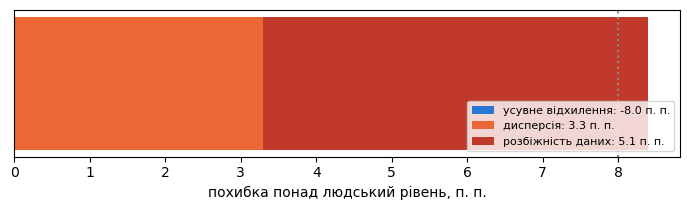

In [24]:
MIX_X, MIX_Y = SOURCES['суміш']
mix_tr, mix_td = split_train_dev(len(MIX_Y), 2000)
XB_tr, yB_tr = flat(MIX_X[mix_tr]), MIX_Y[mix_tr]
XB_td, yB_td = flat(MIX_X[mix_td]), MIX_Y[mix_td]


def model_b():
    return MLPClassifier(hidden_layer_sizes=(256,), max_iter=30, random_state=0)


t0 = time.time()
B = model_b().fit(XB_tr, yB_tr)
pred_B = B.predict(X_dev)
E_B = {'навч': err(B, XB_tr, yB_tr), 'навч_вал': err(B, XB_td, yB_td), 'вал': err(B, X_dev, y_dev)}
print(f'навчено за {time.time() - t0:.0f} с; похибки моделі B, %:', E_B)
DECOMP_B = {'усувне відхилення': round(E_B['навч'] - HUMAN_ERR, 2), 'дисперсія': round(E_B['навч_вал'] - E_B['навч'], 2),
            'розбіжність даних': round(E_B['вал'] - E_B['навч_вал'], 2)}
fig, ax = plt.subplots(figsize=(7, 2.2))
left = 0
for (k, v), c in zip(DECOMP_B.items(), [C1, C2, C4]):
    ax.barh(0, max(v, 0), left=left, color=c, label=f'{k}: {v} п. п.'); left += max(v, 0)
ax.axvline(HUMAN_ERR, color=GREY, ls=':'); ax.set_yticks([]); ax.set_xlabel('похибка понад людський рівень, п. п.')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

### Завдання 6.1

In [25]:
DIAGNOSIS_B = 'розбіжність'
DIAGNOSIS_B_WHY = 'Похибки моделі B: навчальна 0,0 %, навчально-валідаційна 3,3 %, валідаційна 8,4 %. Розбіжність даних = 8,4 − 3,3 = 5,1 п. п., дисперсія = 3,3 п. п., усувне відхилення = −8,0 п. п.. Головна складова — розбіжність даних: на небачених даних суміші модель помиляється у 3,3 % випадків, а на телефонних фото, на яких вона має працювати, — у 8,4 %. Дисперсія — друга за розміром. Більше сканів не допоможе: вони з іншого розподілу, тому розбіжність не зменшать; потрібні дані, схожі на телефонні.'

In [26]:
assert DIAGNOSIS_B in ('відхилення', 'дисперсія', 'розбіжність') and DIAGNOSIS_B_WHY

## 7. Аналіз 100 помилок

Метод лекції 9 (розділи 14–19) і лекції 10 (розділ 42): переглянути помилки **очима**,
позначити, що з кожним фото не так, і порахувати, скільки дасть усунення кожної причини.

Нижче — перші 100 помилок моделі B на валідаційній вибірці (у порядку номерів фото). Над
кожним фото: порядковий номер помилки, **мітка → прогноз моделі**.

**Словник категорій** (можна кілька через `+`):

| категорія | як виглядає |
|---|---|
| `нахил` | цифра помітно повернута |
| `розмиття` | штрихи розмиті, краї нечіткі |
| `низька роздільність` | «сходинки», цифра наче з кількох великих пікселів |
| `тьмяність` | сірий фон, блідий слабкий штрих |
| `відблиск` | частина штриха «вигоріла» до кольору фону |
| `шум` | зерно, крапки по всьому фото |
| `хибна мітка:N` | модель, схоже, права, а мітка хибна; N — правильна, на вашу думку, цифра |
| `нерозбірливо` | людина теж не впевнена |
| `інше` | нічого з переліченого |

Приклад: `'нахил+шум'`, `'хибна мітка:4'`, `'інше'`.

помилок моделі B на валідаційній вибірці: 126 | переглядаємо: 100


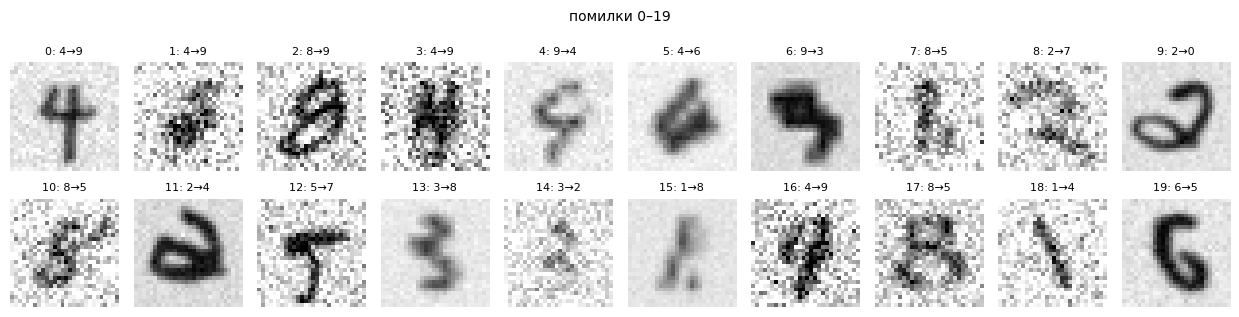

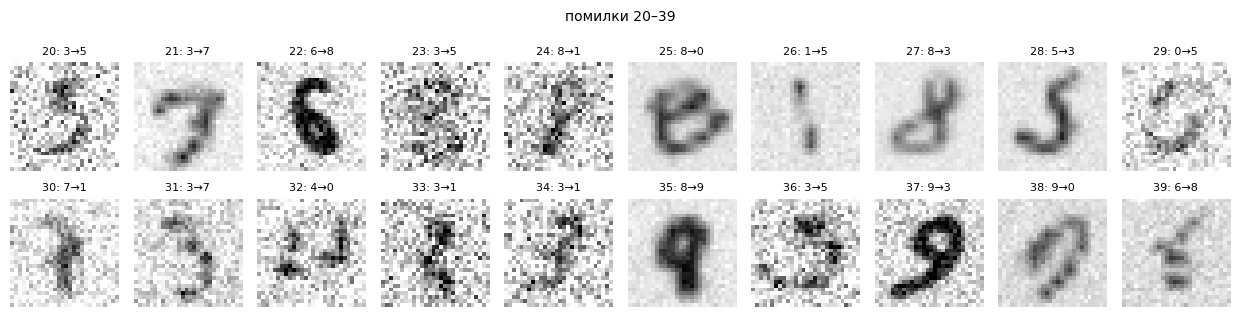

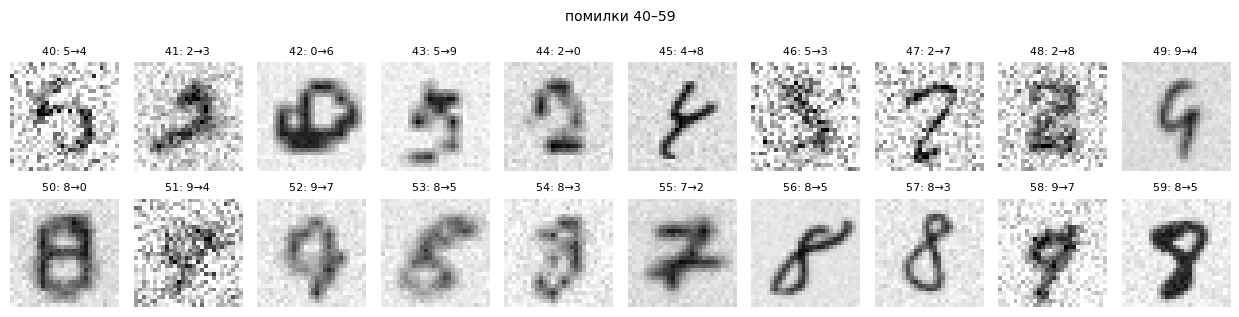

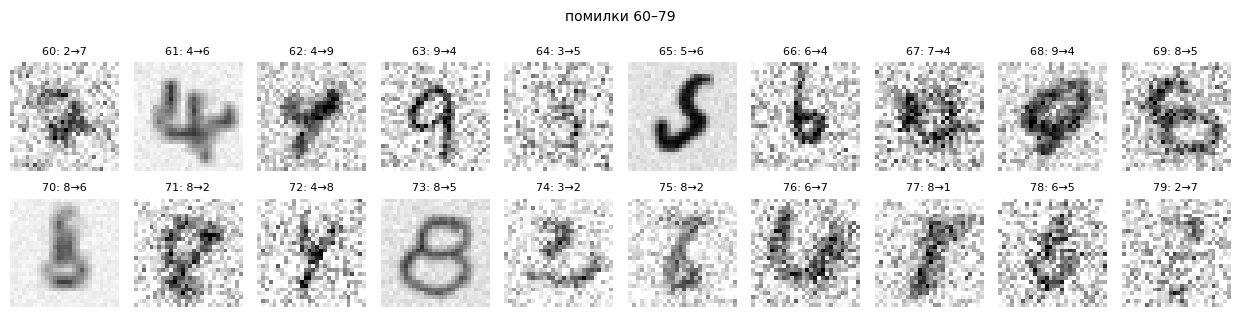

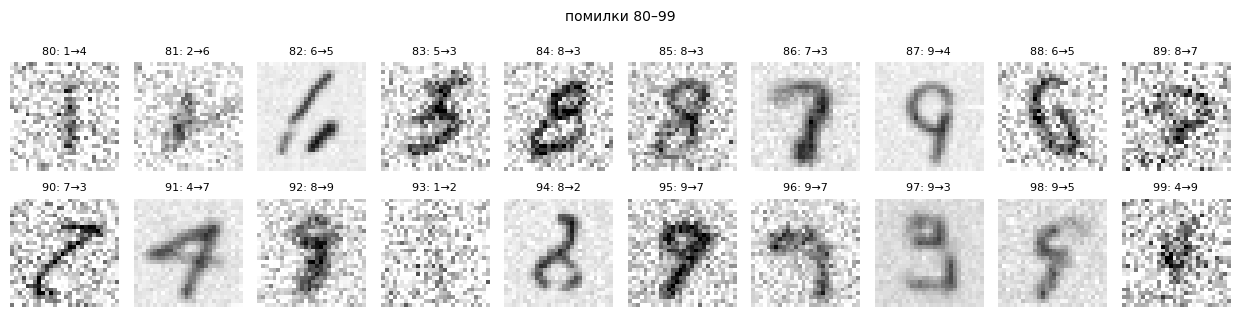

In [27]:
ERR_IDX = np.where(pred_B != DEV_Y)[0][:100]
print('помилок моделі B на валідаційній вибірці:', int((pred_B != DEV_Y).sum()), '| переглядаємо:', len(ERR_IDX))
for page in range(0, len(ERR_IDX), 20):
    ids = ERR_IDX[page:page + 20]
    show_grid(DEV_X[ids], [f'{page + k}: {DEV_Y[i]}→{pred_B[i]}' for k, i in enumerate(ids)], size=1.25,
              title=f'помилки {page}–{page + len(ids) - 1}')

### Завдання 7.1

Заповніть по одному рядку на помилку, у тому самому порядку (якщо помилок менше 100 — лише стільки
рядків, скільки помилок; зайві залиште порожніми). Це найдовша, але й
найважливіша частина роботи: на ній стоїть увесь план.

In [28]:
TAGS = [
    'інше', 'нерозбірливо', 'інше', 'шум', 'розмиття', 'розмиття', 'розмиття', 'шум', 'шум', 'інше',  # 0–9
    'шум', 'інше', 'шум', 'розмиття', 'шум', 'розмиття+нахил', 'шум', 'шум', 'шум+нахил', 'інше', # 10–19
    'шум', 'шум', 'інше', 'шум', 'шум', 'розмиття', 'тьмяність', 'розмиття', 'розмиття', 'шум', # 20–29
    'шум', 'шум', 'шум', 'шум', 'шум', 'розмиття', 'шум', 'інше', 'розмиття', 'шум',   # 30–39
    'шум', 'шум', 'розмиття', 'розмиття', 'розмиття', 'інше', 'шум', 'шум', 'шум', 'розмиття',# 40–49
    'розмиття', 'шум', 'розмиття', 'розмиття', 'розмиття', 'нахил', 'інше', 'інше', 'шум', 'розмиття',   # 50–59
    'шум', 'розмиття', 'шум', 'шум', 'шум', 'інше', 'шум', 'шум', 'шум', 'шум',   # 60–69
    'розмиття', 'шум', 'шум', 'розмиття', 'шум', 'шум', 'шум', 'шум', 'шум', 'шум',   # 70–79
    'шум', 'шум', 'інше', 'шум', 'шум', 'шум', 'розмиття', 'інше', 'шум', 'шум',   # 80–89
    'шум', 'розмиття', 'шум', 'нерозбірливо', 'інше', 'шум', 'шум', 'розмиття', 'шум', 'шум' # 90–99
]

In [29]:
CATS = ['нахил', 'розмиття', 'низька роздільність', 'тьмяність', 'відблиск', 'шум', 'хибна мітка', 'нерозбірливо', 'інше']
assert len(TAGS) >= len(ERR_IDX), f'потрібно {len(ERR_IDX)} рядків, а у списку {len(TAGS)}'
TAGS = TAGS[:len(ERR_IDX)]
parsed, relabel = [], {}
for k, t in enumerate(TAGS):
    assert t.strip(), f'рядок {k} порожній'
    cs = []
    for part in t.split('+'):
        part = part.strip()
        if part.startswith('хибна мітка'):
            cs.append('хибна мітка')
            if ':' in part:
                relabel[int(ERR_IDX[k])] = int(part.split(':')[1])
        else:
            assert part in CATS, f'рядок {k}: невідома категорія «{part}»'
            cs.append(part)
    parsed.append(set(cs))
n = len(parsed)
ERR_TABLE = pd.DataFrame([{'категорія': c, 'помилок': sum(c in p for p in parsed)} for c in CATS])
ERR_TABLE['частка помилок, %'] = (100 * ERR_TABLE['помилок'] / n).round(1)
ERR_TABLE['стеля: на скільки п. п. впаде похибка'] = (E_B['вал'] * ERR_TABLE['помилок'] / n).round(2)
ERR_TABLE = ERR_TABLE.sort_values('помилок', ascending=False).reset_index(drop=True)
print('похибка моделі B на валідаційній:', E_B['вал'], '%; категорії можуть перетинатись, тож сума часток > 100 %')
ERR_TABLE

похибка моделі B на валідаційній: 8.4 %; категорії можуть перетинатись, тож сума часток > 100 %


,категорія,помилок,"частка помилок, %",стеля: на скільки п. п. впаде похибка
0,шум,57,57.0,4.79
1,розмиття,25,25.0,2.10
2,інше,14,14.0,1.18
3,нахил,3,3.0,0.25
4,нерозбірливо,2,2.0,0.17
5,тьмяність,1,1.0,0.08
6,низька роздільність,0,0.0,0.00
7,відблиск,0,0.0,0.00
8,хибна мітка,0,0.0,0.00


**Хибні мітки.** Якщо ви позначили фото як `хибна мітка:N`, нижче похибка моделі B за
**виправленими** мітками валідаційної вибірки. Яка частина похибки — не провина моделі?

In [30]:
DEV_Y_FIXED = DEV_Y.copy()
for i, lab in relabel.items():
    DEV_Y_FIXED[i] = lab
E_B_FIXED = round(100 * float((pred_B != DEV_Y_FIXED).mean()), 2)
print(f'виправлено міток: {len(relabel)}; похибка B: {E_B["вал"]} % → {E_B_FIXED} % за виправленими мітками')

виправлено міток: 0; похибка B: 8.4 % → 8.4 % за виправленими мітками


### Завдання 7.2

Упорядкуйте **до трьох** напрямів роботи за впливом — від найбільшої стелі до меншої. Для хибних
міток рішення інше: їх не «лікують» моделлю, а перевіряють і виправляють розмітку
(лекція 9, розділ 16).

In [31]:
PRIORITY = ['шум', 'розмиття', 'інше']

PRIORITY_WHY = (
    '1) Шум: 57 із 100 помилок, стеля 4,79 п. п. — найбільший напрям, більше половини похибки.'
    'Дія: відібрати фото із шумом, додати синтетичний шум.'
    '2) Розмиття: 25 помилок, стеля 2,10 п. п. Дія: додати розмиті фото і синтез розмиття.'
    '3) Інше: 14 помилок, стеля 1,18 п. п. — чіткі цифри без видимої вади, це звичайна складність/неохайний почерк; модель покращиться зі зростанням і різноманітністю даних. '
    'Решта категорій дають менше 0,3 п. п. (нахил 0,25; нерозбірливо 0,17; тьмяність 0,08), тому в пріоритет не входять.'
)

In [32]:
assert 1 <= len(PRIORITY) <= 3 and all(p in CATS for p in PRIORITY) and PRIORITY_WHY

## 8. Ліки від розбіжності: бюджет — 1000 фото

Варіанти з лекції 10 (розділи 42–43):

1. **докупити** 1000 справжніх телефонних фото з пулу — випадкових;
2. **докупити** 1000 фото, **відібраних без міток**: за вимірюваннями пікселів
   (`image_stats`) або за невпевненістю моделі B (`B.predict_proba`);
3. **синтезувати** 20 000 «телефонних» фото зі сканів функцією `distort` — бюджету не потребує.

Купити можна лише **одну** тисячу. Кожен варіант навчається 30–60 с.

In [33]:
def train_with(extra_X, extra_y):
    """Модель B, навчена на суміші плюс додаткових даних; повертає модель і валідаційну похибку."""
    m = model_b().fit(np.concatenate([XB_tr, flat(extra_X)]), np.concatenate([yB_tr, extra_y]))
    return m, err(m, X_dev, y_dev)


FIX = [{'ліки': 'база: модель B', 'вал': E_B['вал']}]
rand_idx = np.random.default_rng(11).permutation(len(POOL_Y))[:1000]
m_rand, e = train_with(POOL_X[rand_idx], POOL_Y[rand_idx])
FIX.append({'ліки': '+1000 випадкових фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,8.4
1,+1000 випадкових фото з пулу,7.4


### Завдання 8.1. Цілеспрямована покупка

Відберіть 1000 фото з пулу, **не дивлячись на мітки** `POOL_Y`, — так, щоб серед них було
якомога більше фото з категорії-пріоритету. Вимірювання кожного фото пулу вже пораховано:

In [34]:
POOL_STATS = pd.DataFrame(image_stats(POOL_X))
POOL_STATS['впевненість_B'] = B.predict_proba(flat(POOL_X)).max(1)
POOL_STATS.describe().round(3)

,контраст,різкість,нахил_осі,шум,частка_чорнила,впевненість_B
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.684,0.047,-6.421,0.075,0.130,0.946
std,0.106,0.053,28.788,0.050,0.037,0.120
min,0.294,0.004,-88.695,0.023,0.045,0.277
25%,0.612,0.012,-24.647,0.041,0.103,0.975
50%,0.697,0.017,-8.977,0.049,0.125,0.999
75%,0.767,0.080,9.726,0.119,0.152,1.000
max,0.894,0.202,89.929,0.199,0.292,1.000


Підказки: `контраст` — різниця між штрихом і фоном; `різкість` — дисперсія лапласіана
(розмиті й низької роздільності фото мають малу); `шум` — залишок після медіанного фільтра;
`частка_чорнила` — частка пікселів, яскравіших за середину між фоном і штрихом;
`нахил_осі` — кут головної осі цифри (слабка ознака: цифри й самі бувають нахилені);
`впевненість_B` — найбільша ймовірність, яку дає модель B (мала — модель сумнівається).

```python
SELECT = POOL_STATS.sort_values('контраст').index[:1000].to_numpy()   # приклад: найменш контрастні
```

In [35]:
SELECT = POOL_STATS.sort_values('шум', ascending=False).index[:1000].to_numpy()
SELECT_WHY = 'Пріоритет №1 за аналізом помилок — шум (57 із 100 помилок). Тому з пулу відібрано 1000 фото з найбільшим значенням ознаки «шум».'

In [36]:
SELECT = np.asarray(SELECT)
assert SELECT.shape == (1000,) and len(set(SELECT.tolist())) == 1000 and SELECT.min() >= 0 and SELECT.max() < len(POOL_Y)
assert SELECT_WHY
m_sel, e = train_with(POOL_X[SELECT], POOL_Y[SELECT])
FIX.append({'ліки': '+1000 відібраних фото з пулу', 'вал': e}); pd.DataFrame(FIX)

,ліки,вал
0,база: модель B,8.40
1,+1000 випадкових фото з пулу,7.40
2,+1000 відібраних фото з пулу,8.27


**Спостереження:** мій варіант обрати 1000 найшумніших фотографій виявився хибним. Тому я провела нижче різні варіанти підбору додаткових 1000 фото для порівняння

In [37]:
S = POOL_STATS
rng = np.random.default_rng(3)

# половина найшумніших + половина випадкових
noisy = S.sort_values('шум', ascending=False).index[:600].to_numpy()
rest = np.setdiff1d(S.index.to_numpy(), noisy)
SEL_MIX = np.concatenate([noisy[:500], rng.choice(rest, 500, replace=False)])

# шум + невпевненість моделі B
score = S['шум'].rank() + (1 - S['впевненість_B']).rank()
SEL_NOISE_UNC = score.sort_values(ascending=False).index[:1000].to_numpy()

# лише невпевненість моделі B
SEL_UNC = S.sort_values('впевненість_B').index[:1000].to_numpy()

VARIANTS = {'шум + випадкові': SEL_MIX,
            'шум + невпевненість B': SEL_NOISE_UNC,
            'лише невпевненість B': SEL_UNC}
TRY = [{'варіант': 'для порівняння: випадкові', 'вал': FIX[1]['вал']},
       {'варіант': 'для порівняння: найшумніші 1000', 'вал': FIX[2]['вал']}]
for name, ids in VARIANTS.items():
    _, e = train_with(POOL_X[ids], POOL_Y[ids])
    TRY.append({'варіант': name, 'вал': e})
pd.DataFrame(TRY)

,варіант,вал
0,для порівняння: випадкові,7.40
1,для порівняння: найшумніші 1000,8.27
2,шум + випадкові,8.53
3,шум + невпевненість B,7.67
4,лише невпевненість B,7.47


**Остаточний відбір** За результатами порівняння беру відбір за невпевненістю моделі B: він найкращий серед цілеспрямованих (7,47 %) і практично дорівнює випадковим (7,40 %). Нижче він замінює перший (невдалий) відбір за шумом.

In [38]:
SELECT = SEL_UNC
SELECT_WHY = 'Пріоритет №1 був шум, але відбір лише за шумом дав 8,27 % (база 8,40 %), гірше за випадкові фото (7,40 %); суміш «шум + випадкові» — 8,53 %, шум + невпевненість B — 7,67 %. Тому остаточно відібрано 1000 фото, у яких модель B найменш упевнена.'

In [39]:
SELECT = np.asarray(SELECT)
assert SELECT.shape == (1000,) and len(set(SELECT.tolist())) == 1000 and SELECT.min() >= 0 and SELECT.max() < len(POOL_Y)
assert SELECT_WHY

e_unc = next(r['вал'] for r in TRY if r['варіант'] == 'лише невпевненість B')
FIX = [r for r in FIX if r['ліки'] != '+1000 відібраних фото з пулу']
FIX.append({'ліки': '+1000 відібраних фото з пулу (невпевненість B)', 'вал': e_unc})

### Завдання 8.2. Синтез

Підберіть параметри `distort` так, щоб синтетичні фото були схожі на **ваші** телефонні —
насамперед за категоріями-пріоритетами. Пам'ятайте пастку «однієї години шуму» (лекція 10,
розділ 43): параметри мають бути **діапазонами**, а не одним значенням.

```python
SYN = dict(angle=(15, 30), blur=(0.4, 0.8), background=(0.05, 0.15), contrast=(0.7, 0.9), noise=(0.02, 0.05))
SYN_SHARE = 0.6     # частка сканів, які спотворюємо (решта лишається чистою)
```

Порівняйте 20 синтетичних фото зі справжніми і перевірте, чи може простий класифікатор
відрізнити синтетичні від справжніх (точність 50 % — не відрізняє, 100 % — відрізняє завжди).

In [40]:
SYN = dict(blur=(0.4, 1.5),
           background=(0.04, 0.16),
           contrast=(0.65, 0.85),
           noise=(0.01, 0.15))
SYN_SHARE = 1.0

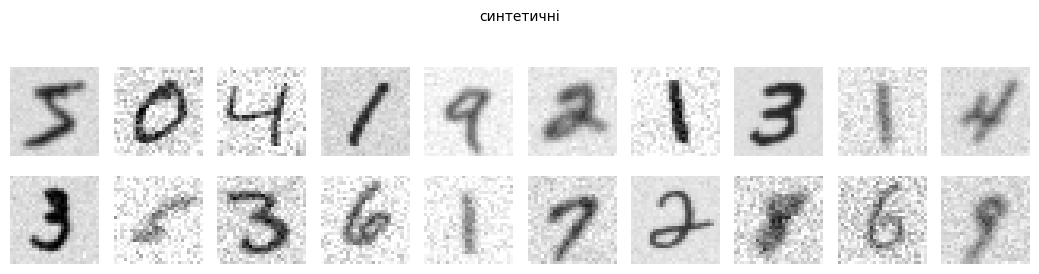

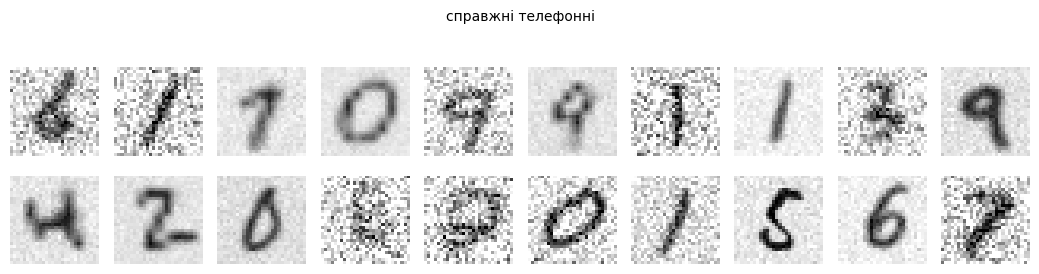

класифікатор відрізняє синтетичні фото від справжніх із точністю 58.1 %


,ліки,вал
0,база: модель B,8.40
1,+1000 випадкових фото з пулу,7.40
2,+1000 відібраних фото з пулу (невпевненість B),7.47
3,+20 000 синтетичних фото,6.07


In [41]:
assert SYN, 'задайте параметри синтезу'
SYN_X = distort(SCAN_X, seed=42, share=SYN_SHARE, **SYN)
show_grid(SYN_X[:20], title='синтетичні'); show_grid(PHONE_X[:20], title='справжні телефонні')
Xd = np.concatenate([flat(PHONE_X[:1500]), flat(SYN_X[:1500])]); yd = np.r_[np.zeros(1500), np.ones(1500)]
SYN_DISCR = round(100 * float(cross_val_score(LogisticRegression(max_iter=500), Xd, yd, cv=5).mean()), 1)
print('класифікатор відрізняє синтетичні фото від справжніх із точністю', SYN_DISCR, '%')
m_syn, e = train_with(SYN_X, SCAN_Y)
FIX.append({'ліки': '+20 000 синтетичних фото', 'вал': e}); pd.DataFrame(FIX)

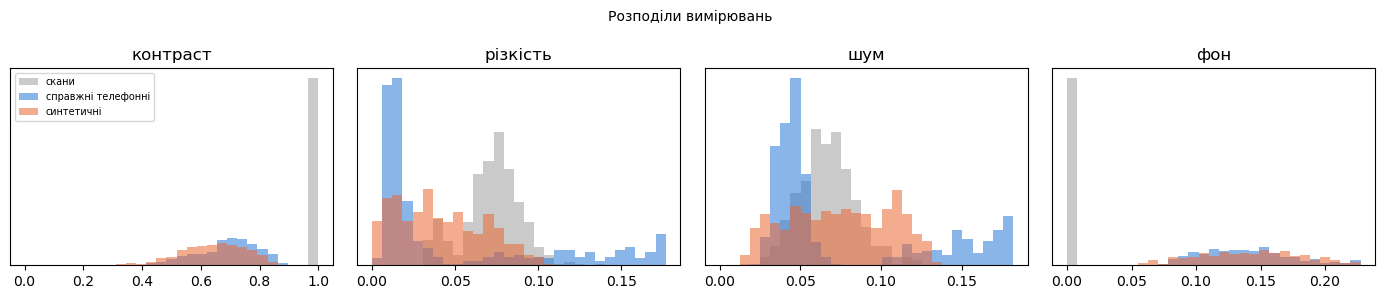

In [42]:
N = 500
real = pd.DataFrame(image_stats(PHONE_X[:N]))
scan = pd.DataFrame(image_stats(SCAN_X[:N]))
syn = pd.DataFrame(image_stats(SYN_X[:N]))
for df, X in ((real, PHONE_X[:N]), (scan, SCAN_X[:N]), (syn, SYN_X[:N])):
    df['фон'] = np.median(X.reshape(len(X), -1), axis=1) / 255

feats = ['контраст', 'різкість', 'шум', 'фон']
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, ft in zip(axs, feats):
    hi = np.percentile(np.r_[real[ft], scan[ft], syn[ft]], 99)
    bins = np.linspace(0, hi, 30)
    ax.hist(scan[ft].clip(upper=hi), bins, alpha=.45, color=GREY, label='скани')
    ax.hist(real[ft].clip(upper=hi), bins, alpha=.55, color=C1, label='справжні телефонні')
    ax.hist(syn[ft].clip(upper=hi), bins, alpha=.55, color=C2, label='синтетичні')
    ax.set_title(ft); ax.set_yticks([])
axs[0].legend(fontsize=7)
fig.suptitle('Розподіли вимірювань', fontsize=10)
plt.tight_layout(); plt.show()

In [43]:
summary = pd.DataFrame({'скани': scan[feats].median(), 'справжні телефонні': real[feats].median(), 'синтетичні': syn[feats].median()}).round(3)
print('медіани вимірювань:')
display(summary)

медіани вимірювань:


,скани,справжні телефонні,синтетичні
контраст,0.992,0.700,0.648
різкість,0.074,0.018,0.037
шум,0.066,0.049,0.075
фон,0.000,0.137,0.143


Вище три розподіли вимірювань: скани (сірі), справжні телефонні фото (сині) і синтетичні (помаранчеві). 
Мета підбору — щоб помаранчеві накладались на сині, а не на сірі.

* **Контраст і фон.** У сканів контраст ≈ 0,99 і фон 0; у справжніх фото контраст ≈ 0,70 і фон ≈ 0,14. Тому в `distort` задано `contrast=(0.65, 0.85)` і `background=(0.04, 0.16)`.
* **Розмиття.** Різкість справжніх фото (≈ 0,018) набагато менша, ніж у сканів (≈ 0,074), тому `blur=(0.4, 1.5)`.
* **Шум.** Справжні фото дуже різні: частина майже без шуму, частина дуже зашумлена, тому `noise=(0.01, 0.15)`.
* **Нахил** не додано: у розмітці помилок він трапився лише в 3 випадках із 100.

### Завдання 8.3. Остаточна модель і план

Зберіть остаточну модель з того, що спрацювало (одна тисяча куплених фото + синтез за
бажанням), і **один раз** оцініть її на тестовій вибірці.

In [44]:
FINAL_PURCHASE = 'випадкові'
FINAL_SYNTH = True

In [45]:
assert FINAL_PURCHASE in ('випадкові', 'відібрані', '') and FINAL_SYNTH in (True, False)
parts_X, parts_y = [], []
if FINAL_PURCHASE:
    ids = rand_idx if FINAL_PURCHASE == 'випадкові' else SELECT
    parts_X.append(POOL_X[ids]); parts_y.append(POOL_Y[ids])
if FINAL_SYNTH:
    parts_X.append(SYN_X); parts_y.append(SCAN_Y)
FINAL, e = train_with(np.concatenate(parts_X), np.concatenate(parts_y)) if parts_X else (B, E_B['вал'])
FIX.append({'ліки': f'остаточна: покупка «{FINAL_PURCHASE or "—"}», синтез {"так" if FINAL_SYNTH else "ні"}', 'вал': e})
E_FINAL_TEST = evaluate_on_test(FINAL, 'остаточна модель')
print('остаточна модель: валідаційна', e, '%, тестова', E_FINAL_TEST, '%')
pd.DataFrame(FIX)

остаточна модель: валідаційна 6.2 %, тестова 6.13 %


,ліки,вал
0,база: модель B,8.40
1,+1000 випадкових фото з пулу,7.40
2,+1000 відібраних фото з пулу (невпевненість B),7.47
3,+20 000 синтетичних фото,6.07
4,"остаточна: покупка «випадкові», синтез так",6.20


In [46]:
PLAN = [
    'Перейти з виробничої моделі на модель B, навчену на суміші сканів і телефонних фото: '
    'валідаційна похибка 14,4 % → 8,4 % (очікувано −6,0 п. п.). Діагноз B — розбіжність даних , тому нові скани не потрібні.',

    'Додати 20 000 синтетичних «телефонних» фото — без витрат бюджету: 8,4 % → 6,07 % (−2,3 п. п.). '
    'Класифікатор відрізняє синтетичні фото від справжніх з точністю 58,1 %, тобто вони достатньо схожі.',

    'Докупити 1000 випадкових телефонних фото з пулу (окремо було: 8,4 % → 7,4 %, −1,0 п. п.). '
    'Разом із синтезом (6,20 %) додаткової переваги не доведено, тож цей крок другорядний: робити його, лише якщо бюджет вже закладено. '
    'Цілеспрямований відбір (за шумом 8,27 %, за невпевненістю моделі 7,47 %) випадкових не допоміг.',

    'Підтвердити результат на тестовій вибірці один раз.',

    'Коли бюджет вичерпано: повторити аналіз 100 помилок вже для остаточної моделі. Раніше найбільші стелі '
    'були у шуму (4,79 п. п.) і розмиття (2,10 п. п.), тож далі розширювати діапазони '
    'noise і blur у distort і наближати SYN_DISCR до 50 % (зараз 58,1 %). Окремо уточнити людський рівень , щоб знати, скільки ще можна виграти.',
]


In [47]:
assert len(PLAN) >= 3, 'план має містити щонайменше три кроки'
for k, s in enumerate(PLAN, 1):
    print(k, s)

1 Перейти з виробничої моделі на модель B, навчену на суміші сканів і телефонних фото: валідаційна похибка 14,4 % → 8,4 % (очікувано −6,0 п. п.). Діагноз B — розбіжність даних , тому нові скани не потрібні.
2 Додати 20 000 синтетичних «телефонних» фото — без витрат бюджету: 8,4 % → 6,07 % (−2,3 п. п.). Класифікатор відрізняє синтетичні фото від справжніх з точністю 58,1 %, тобто вони достатньо схожі.
3 Докупити 1000 випадкових телефонних фото з пулу (окремо було: 8,4 % → 7,4 %, −1,0 п. п.). Разом із синтезом (6,20 %) додаткової переваги не доведено, тож цей крок другорядний: робити його, лише якщо бюджет вже закладено. Цілеспрямований відбір (за шумом 8,27 %, за невпевненістю моделі 7,47 %) випадкових не допоміг.
4 Підтвердити результат на тестовій вибірці один раз.
5 Коли бюджет вичерпано: повторити аналіз 100 помилок вже для остаточної моделі. Раніше найбільші стелі були у шуму (4,79 п. п.) і розмиття (2,10 п. п.), тож далі розширювати діапазони noise і blur у distort і наближати SYN

## 9. Аналіз помилок за частинами

Сервіс отримує не вирізану цифру, а фото бланка 56 × 56: цифра може бути будь-де, поруч — плями
(лекція 10, розділи 53–54). Конвеєр:

* **A** — локалізатор без навчання (`locate`): знаходить цифру і вирізає 28 × 28;
* **Cʹ** — класифікатор, навчений на суміші і на копіях, зсунутих на 1–2 пікселі.

Тест книжки: підставте замість виходу A **ідеальний** виріз (справжнє положення цифри). Якщо
відповідь стала правильною — помилка на совісті A, якщо ні — Cʹ.

Cʹ навчено за 36 с


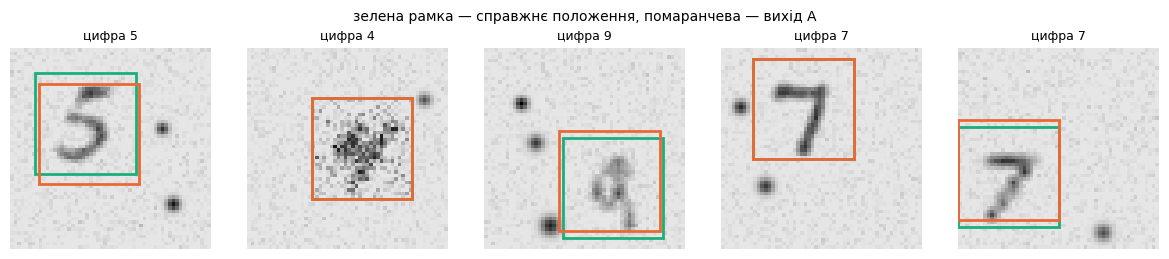

In [48]:
CANVAS = INFO['полотна']
CX, CPOS = make_canvas(DEV_X, 500 + VARIANT, blobs=tuple(CANVAS['плями']), lines=CANVAS['лінії'])
t0 = time.time()
Cp = model_b().fit(np.concatenate([XB_tr, flat(shifted_copies(MIX_X[mix_tr][::2], 5))]), np.concatenate([yB_tr, yB_tr[::2]]))
POS_A = locate(CX)
print(f'Cʹ навчено за {time.time() - t0:.0f} с')
fig, axs = plt.subplots(1, 5, figsize=(12, 2.6))
for k, ax in enumerate(axs):
    ax.imshow(CX[k], cmap='gray_r', vmin=0, vmax=1)
    for (r0, c0), col in [(CPOS[k], C3), (POS_A[k], C2)]:
        ax.add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), 28, 28, fill=False, color=col, lw=2))
    ax.set_title(f'цифра {DEV_Y[k]}', fontsize=9); ax.axis('off')
fig.suptitle('зелена рамка — справжнє положення, помаранчева — вихід A', fontsize=10); plt.tight_layout(); plt.show()

### Завдання 9.1

Допишіть три рядки: прогноз системи на вирізах A, прогноз Cʹ на ідеальних вирізах і маску помилок.
Функції: `crop(CX, POS_A)`, `crop(CX, CPOS)`, `flat(...)`, `Cp.predict(...)`.

In [49]:
pred_sys = Cp.predict(flat(crop(CX, POS_A)))
pred_ideal = Cp.predict(flat(crop(CX, CPOS)))
wrong_sys = pred_sys != DEV_Y

In [50]:
blame_A = int((wrong_sys & (pred_ideal == DEV_Y)).sum()); blame_C = int((wrong_sys & (pred_ideal != DEV_Y)).sum())
PARTS = {'похибка_системи': round(100 * float(wrong_sys.mean()), 2), 'помилок': int(wrong_sys.sum()), 'вина_A': blame_A, 'вина_C': blame_C,
         'A_влучив': round(100 * float((np.abs(POS_A - CPOS) <= 2).all(1).mean()), 1)}
PARTS

{'похибка_системи': 12.33,
 'помилок': 185,
 'вина_A': 88,
 'вина_C': 97,
 'A_влучив': 94.5}

In [51]:
PARTS_VERDICT = 'C'
E_IDEAL = round(100 * float((pred_ideal != DEV_Y).mean()), 2)
PARTS_WHY = (
    f'Система помилилась у {PARTS["помилок"]} випадках ({PARTS["похибка_системи"]} %). '
    f'У {PARTS["вина_A"]} із них на ідеальному вирізі відповідь стає правильною (вина A), '
    f'у {PARTS["вина_C"]} — лишається хибною (вина Cʹ). Cʹ винен частіше: '
    f'навіть з ідеальним локалізатором Cʹ помиляється у {E_IDEAL} %. '
    f'Різниця у кількості ({PARTS["вина_C"]} проти {PARTS["вина_A"]}) невелика, тому рішення спирається на стелю: '
    f'ідеальний A зняв би лише {round(PARTS["похибка_системи"] - E_IDEAL, 2)} п. п., а решта {E_IDEAL} % залежить від Cʹ. '
    'Що змінити в Cʹ: навчати його не лише на суміші, а й на синтетичних телефонних фото. '
    'Другим кроком — звузити роботу A: прибирати плями-завади перед пошуком цифри.'
)

In [52]:
print(PARTS_WHY)

Система помилилась у 185 випадках (12.33 %). У 88 із них на ідеальному вирізі відповідь стає правильною (вина A), у 97 — лишається хибною (вина Cʹ). Cʹ винен частіше: навіть з ідеальним локалізатором Cʹ помиляється у 7.47 %. Різниця у кількості (97 проти 88) невелика, тому рішення спирається на стелю: ідеальний A зняв би лише 4.86 п. п., а решта 7.47 % залежить від Cʹ. Що змінити в Cʹ: навчати його не лише на суміші, а й на синтетичних телефонних фото. Другим кроком — звузити роботу A: прибирати плями-завади перед пошуком цифри.


In [53]:
assert PARTS_VERDICT in ('A', 'C') and PARTS_WHY

## 10. Звіт колеги на критику

Колега з іншої команди розв'язував ту саму задачу на своїх даних (варіанта з такими числами
в групі немає) і надіслав звіт. У ньому **сім** методичних помилок. Знайдіть щонайменше
**п'ять**: для кожної — номер пункту, у чому помилка і як треба було зробити (з посиланням
на розділ книжки).

> **Звіт: модель читання цифр із фото, версія 2**
>
> **1. Поділ даних.** Перемішав усі 26 000 зображень (20 000 сканів і 6000 фото) і випадково
> відклав по 10 % на валідаційну і тестову вибірки.
>
> **2. Людський рівень.** Я і троє колег підписали по 50 фото; середня похибка — 6 %, найкраща — 1 %.
> Модель на валідаційній вибірці помиляється у 2,4 % випадків, тобто вже краща за людей:
> усувного відхилення немає, працювати над моделлю далі немає сенсу.
>
> **3. Діагноз.** На фото, які надсилають клієнти, похибка — 11,8 %; на навчально-валідаційній
> вибірці — 2,9 %, на навчальній — 0,3 %. Це перенавчання (висока дисперсія). Посилив
> регуляризацію (alpha = 1): навчальна 2,1 %, фото клієнтів — 12,6 %. Дивно, що не допомогло.
>
> **4. Аналіз помилок.** Переглянув 100 помилок на фото клієнтів: 40 із них розмиті. Якщо
> усунути розмиття, похибка зменшиться на 40 % — до 0,4 %. Тому розмиття — пріоритет номер один.
>
> **5. Синтез.** Сфотографував чистий аркуш у кафе і наклав цей самий фон на всі 20 000 сканів.
> На валідаційній вибірці з пункту 1 похибка впала з 2,4 % до 2,1 % — синтез працює.
>
> **6. Вибір моделі.** Порівняв 12 варіантів моделі на тестовій вибірці й обрав найкращий —
> 9,7 %. Це і є очікувана похибка в клієнтів.
>
> **7. Аналіз за частинами.** Підставив замість відповіді класифікатора правильну цифру — і система
> стала правильною в 100 % випадків. Отже, усі помилки — від класифікатора, локалізатор не винен.

In [54]:
CRITIQUE = [
    {'пункт': 1,
     'помилка': 'Валідаційну і тестову вибірки відкладено випадково з суміші 20 000 сканів і 6000 фото. Вони складаються переважно зі сканів, а не з того розподілу, де працюватиме сервіс.',
     'як_правильно': 'Валідаційна і тестова вибірки мають бути лише з телефонних фото (цільовий розподіл), скани йдуть лише у навчання (лекція 10, розд. 36). Інакше похибка занижена.'},

    {'пункт': 2,
     'помилка': 'Модель (2,4 %) названо кращою за людей і зроблено висновок «усувного відхилення немає». Але людський рівень — це найкращий результат (1 %), а не середній (6 %); 2,4 % гірше за 1 %. ',
     'як_правильно': 'Брати найкращий людський результат як оцінку оптимальної похибки: усувне відхилення ≈ 2,4 − 1 = 1,4 п. п..'},

    {'пункт': 3,
     'помилка': 'Діагноз «перенавчання» хибний: розклад навч 0,3 - навч-вал 2,9 - вал 11,8 дає дисперсію 2,6 п. п., а розбіжність даних 8,9 п. п. Головна складова — розбіжність, тому регуляризація не допомогла.',
     'як_правильно': 'Розкласти похибку на відхилення, дисперсію і розбіжність даних і лікувати найбільшу: додавати дані, схожі на телефонні фото.'},

    {'пункт': 4,
     'помилка': 'Арифметика: якщо розмиття — причина 40 зі 100 помилок, то стеля — 40 % від 11,8 %, тобто 4,7 п. п. (11,8 -> 7,1 %), а не «до 0,4 %». Вираз «зменшиться на 40 % — до 0,4 %» помилковий.',
     'як_правильно': 'Стеля = частка помилок категорії × загальна похибка: 0,40 × 11,8 = 4,7 п. п. Це верхня межа.'},

    {'пункт': 5,
     'помилка': 'Синтез зроблено одним фоном з одного кафе, накладеним на всі 20 000 сканів. Модель вчиться на єдиному варіанті й не узагальнюється; до того ж ефект виміряно на валідаційній, переважно зі сканів.',
     'як_правильно': 'Параметри синтезу задавати діапазонами (різні фони, яскравість, розмиття, шум) і оцінювати лише на телефонних фото.'},

    {'пункт': 6,
     'помилка': '12 варіантів моделі порівняно на тестовій вибірці й обрано найкращий (9,7 %), після чого цю саму цифру названо очікуваною похибкою. Вибір за тестом робить оцінку занадто оптимістичною.',
     'як_правильно': 'Порівнювати варіанти на валідаційній вибірці, а тестову використати один раз для остаточної моделі.'},

    {'пункт': 7,
     'помилка': 'Тест частин зроблено навиворіт: замість виходу локалізатора підставлено правильну цифру, і система, звісно, стала правильною на 100 %. Висновок «локалізатор не винен» з цього не випливає.',
     'як_правильно': 'Підставляти ідеальний вихід компонента A (правильний виріз навколо цифри) і дивитись, чи відповідь класифікатора стала правильною, порахувавши окремо вину A і вину класифікатора.'},
]

In [55]:
assert len(CRITIQUE) >= 5 and all(c.get('помилка') and c.get('як_правильно') for c in CRITIQUE), 'потрібно щонайменше 5 знайдених помилок'
pd.DataFrame(CRITIQUE)

,пункт,помилка,як_правильно
0,1,Валідаційну і тестову вибірки відкладено випадково з суміші 20 000 сканів і 6000 фото....,"Валідаційна і тестова вибірки мають бути лише з телефонних фото (цільовий розподіл), с..."
1,2,"Модель (2,4 %) названо кращою за людей і зроблено висновок «усувного відхилення немає»...",Брати найкращий людський результат як оцінку оптимальної похибки: усувне відхилення ≈ ...
2,3,"Діагноз «перенавчання» хибний: розклад навч 0,3 - навч-вал 2,9 - вал 11,8 дає дисперсі...","Розкласти похибку на відхилення, дисперсію і розбіжність даних і лікувати найбільшу: д..."
3,4,"Арифметика: якщо розмиття — причина 40 зі 100 помилок, то стеля — 40 % від 11,8 %, тоб...","Стеля = частка помилок категорії × загальна похибка: 0,40 × 11,8 = 4,7 п. п. Це верхня..."
4,5,"Синтез зроблено одним фоном з одного кафе, накладеним на всі 20 000 сканів. Модель вчи...","Параметри синтезу задавати діапазонами (різні фони, яскравість, розмиття, шум) і оціню..."
5,6,"12 варіантів моделі порівняно на тестовій вибірці й обрано найкращий (9,7 %), після чо...","Порівнювати варіанти на валідаційній вибірці, а тестову використати один раз для остат..."
6,7,Тест частин зроблено навиворіт: замість виходу локалізатора підставлено правильну цифр...,"Підставляти ідеальний вихід компонента A (правильний виріз навколо цифри) і дивитись, ..."


---
# Частина 3. Звіт (0,5 бала)
---
## 11. Звіт

Відповідайте **числами з цього ноутбука**, а не загальними словами.

1. **Діагноз виробничої моделі.** Назвіть три похибки і три складові розкладу. Чому
   навчально-валідаційну вибірку взято саме з того джерела?
2. **Людський рівень.** Ваша похибка на 50 фото і найкраща в групі для вашого варіанта.
   Чи змінив би діагноз людський рівень 0 %? А 5 %?
3. **Крива навчання.** Чи допоможуть дані того самого джерела? Що на графіку це показує?
4. **Дії.** Які дві дії допомогли, на скільки п. п.? Що сталося з контрольною дією і чому?
5. **Модель B.** Яка складова її похибки головна і чому більше сканів її не зменшить?
6. **Аналіз помилок.** Три пріоритети зі стелями. Яка частка похибки — хибні мітки?
   Чи варто виправляти мітки валідаційної вибірки?
7. **Ліки.** Що дало найбільший виграш і чи вклався він у стелю з пункту 6? Наскільки
   синтетичні фото відрізняються від справжніх?
8. **Тест.** Валідаційна і тестова похибки остаточної моделі. Скільки разів ви зверталися до
   тестової вибірки?
9. **Аналіз за частинами.** Хто винен частіше — A чи Cʹ — і що ви зробите першим?
10. **Звіт колеги.** Яка з його помилок найдорожча для замовника і чому?

In [56]:
REPORT = '''
1. Діагноз виробничої моделі. Виробнича модель навчена на телефонних фото. Похибки: навчальна 0,0 %, навчально-валідаційна 13,75 %, валідаційна (телефонні фото) 14,4 %; людський рівень 8,0 %. Розклад: усувне відхилення 0,0 − 8,0 = −8,0 п. п., дисперсія 13,75 − 0,0 = 13,75 п. п., розбіжність даних 14,4 − 13,75 = 0,65 п. п. Діагноз: дисперсія. Навчально-валідаційну вибірку (400 телефонних фото) взято з того самого джерела, що й навчальну, щоб модель її не бачила, але дані були такого ж типу: тоді різниця між двома похибками показує лише дисперсію і не змішується з розбіжністю даних.

2. Людський рівень. Моя похибка на 50 фото — 8,0 % (4 помилки: фото 9, 26, 29, 30). Найкращий результат у групі для цього варіанта я не знаю, тому використала власний; Діагноз від людського рівня не залежить: навчальна похибка 0 %, тож відхилення при людському рівні 0 % було б 0,0 п. п., а при 5 % — −5,0 п. п..

3. Крива навчання. Дані того самого джерела допоможуть. Навчальна похибка весь час 0 %, а навчально-валідаційна падає: 24,50 % (160 прикладів) - 18,00 % (400) - 16,25 % (800) - 13,75 % (1600). Розрив між кривими великий (13,75 п. п.) і ще не закрився; валідаційна лінія (14,4 %) лежить майже на навчально-валідаційній, тож розбіжність даних мала.

4. Дії. Допомогли дві дії проти дисперсії. Аугментація зсувами ±2 px: дисперсія −2,50 п. п., валідаційна 14,40 - 11,33 % (−3,07 п. п.), навчальна 0 %. Регуляризація alpha = 1: дисперсія −2,06 п. п., валідаційна 14,40 - 12,47 % (−1,93 п. п.), але навчальна зросла до 1,56 %. Контрольна дія (більша мережа MLP(1024), ліки від відхилення) не допомогла: навчальна лишилась 0 %, дисперсія +0,75 п. п. (13,75 - 14,50 %), валідаційна змінилась лише на −0,73 п. п. Прогноз справдився: відхилення в нас уже нульове, тож збільшення моделі нічого не дає.

5. Модель B. Похибки: навчальна 0,0 %, навчально-валідаційна 3,3 %, валідаційна 8,4 %. Складові: відхилення −8,0 п. п., дисперсія 3,3 п. п., розбіжність даних 8,4 − 3,3 = 5,1 п. п. Головна — розбіжність даних: на суміші модель помиляється рідко, а на телефонних фото — значно частіше. Більше сканів її не зменшить, бо вони з іншого розподілу, ніж телефонні фото, тож розбіжності не торкаються; потрібні дані, схожі на телефонні.

6. Аналіз помилок. З 100 переглянутих помилок: шум 57 (стеля 4,79 п. п.), розмиття 25 (2,10 п. п.), інше 14 (1,18 п. п.); решта категорій менше 0,3 п. п. (нахил 0,25, нерозбірливо 0,17, тьмяність 0,08). Три пріоритети: шум, розмиття, інше. Хибних міток не знайдено, тож виправляти розмітку валідаційної вибірки не потрібно.

7. Ліки. Найбільший виграш дав синтез 20 000 фото через distort (blur 0,4–1,5; contrast 0,65–0,85; background 0,04–0,16; noise 0,01–0,15): валідаційна 8,40 - 6,07 % (−2,33 п. п.). Випадкові 1000 фото: 7,40 %; відбір за невпевненістю B — 7,47 %; відбір за шумом — 8,27 %. Класифікатор відрізняє синтетичні фото від справжніх з точністю 58,1 %.

8. Тест. Остаточна модель (суміш + 1000 випадкових фото + 20 000 синтетичних): валідаційна 6,20 %, тестова 6,13 %. До тестової вибірки я зверталась 1 раз.

9. Аналіз за частинами. Система помилилась у 185 випадках (12,33 %): вина A — 88, вина Cʹ — 97; A влучив у ±2 пікселі у 94,5 % випадків. Cʹ винен частіше: навіть з ідеальним локалізатором Cʹ помиляється у 7.47 %. Першим покращувати Cʹ: навчати на синтетичних телефонних фото; другим кроком — звузити роботу A (прибирати плями-завади перед пошуком цифри).

10. Звіт колеги. Найдорожча помилка — пункт 1: валідаційна і тестова вибірки відкладені випадково з суміші, де ≈ 77 % — скани, а не телефонні фото. Через це всі наступні числа колеги не описують, як сервіс працюватиме в клієнтів, а помилку не можна виправити без перерахунку всього. З неї тягнуться й хибний діагноз і марна регуляризація. Інші помилки: людський рівень, арифметика стелі, синтез одним фоном, вибір моделі на тестовій вибірці, тест частин навиворіт.

Декларація про використання ШІ: Під час роботи я користувалась ШІ-асистентом Claude Code. Він пояснював поняття, пропонував варіанти дій, допомагав сформулювати тексти висновків. Я самостійно перевіряла числа, вносила правки в тексти і відповідаю за остаточну версію.
'''

### Декларація про використання штучного інтелекту

Наприкінці звіту зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; не дозволено видавати чуже за своє.

In [57]:
def _num(d):
    return {k: (round(float(v), 4) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in d.items()}


result = {
    'студент': STUDENT_NAME, 'номер': LIST_NUMBER, 'варіант': VARIANT,
    'версія_sklearn': sklearn.__version__,
    'джерело_навч_вал': TRAIN_SOURCE, 'чому_навч_вал': WHY_TRAIN_DEV,
    'людина': {'відповіді': HUMAN_ANSWERS, 'похибка': HUMAN_ERR},
    'виробнича': {'похибки': _num(E_PROD), 'розклад': _num(DECOMP_PROD), 'діагноз': DIAGNOSIS, 'доказ': DIAGNOSIS_WHY},
    'крива': CURVE.to_dict('records'), 'більше_тих_самих_даних': MORE_SAME_DATA_HELPS, 'крива_чому': CURVE_WHY,
    'дії': ACT_TABLE.round(2).to_dict('records'), 'дії_висновок': ACTIONS_CONCLUSION,
    'B': {'похибки': _num(E_B), 'розклад': _num(DECOMP_B), 'діагноз': DIAGNOSIS_B, 'чому': DIAGNOSIS_B_WHY,
          'за_виправленими_мітками': E_B_FIXED, 'виправлено_міток': len(relabel)},
    'аналіз_помилок': {'мітки': TAGS, 'номери_фото': ERR_IDX.tolist(), 'таблиця': ERR_TABLE.to_dict('records'),
                       'пріоритет': PRIORITY, 'чому': PRIORITY_WHY},
    'ліки': FIX, 'відбір': {'номери': SELECT.tolist(), 'чому': SELECT_WHY},
    'синтез': {'параметри': {k: list(v) for k, v in SYN.items()}, 'частка': SYN_SHARE, 'розрізнення_%': SYN_DISCR},
    'остаточна': {'покупка': FINAL_PURCHASE, 'синтез': FINAL_SYNTH, 'тест': E_FINAL_TEST, 'звернень_до_тесту': len(_TEST_CALLS)},
    'план': PLAN,
    'частини': PARTS, 'частини_висновок': PARTS_VERDICT, 'частини_чому': PARTS_WHY,
    'критика': CRITIQUE, 'звіт': REPORT,
}
fname = 'lr7_результат_%02d.json' % LIST_NUMBER
with open(fname, 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('збережено', fname)

збережено lr7_результат_15.json


---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок (повний прогін — 10–15 хвилин).
* Усі `assert` зелені.
* Файл `lr7_результат_NN.json` створено; здайте його разом із ноутбуком.
* Тестову вибірку використано **один** раз.
* У звіті — числа, а не загальні формулювання; декларацію про ШІ заповнено.